# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/irene1407/ML-1/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### Purpose

This playbook converts the validated March-to-April ranking-risk analysis into a ranked editorial review queue.

The queue uses a client-grouped holdout split. Logistic Regression is used as an interpretable decision-support model. The model score is combined with search exposure to prioritize review candidates.

A higher priority score means an item deserves earlier human investigation. It does not mean a decline is certain or that an edit will improve performance.

### Reason codes and action mapping

| Archetype | Reason code | Suggested action |
|---|---|---|
| High visibility + weak CTR | HIGH_VISIBILITY_CTR_GAP | Review title, meta description and search intent match |
| High visibility + elevated risk | HIGH_VISIBILITY_POSITION_RISK | Conduct an editorial refresh audit |
| Elevated risk + low exposure | RISK_WITH_LOW_EXPOSURE | Investigate demand and monitor before editing |
| High visibility + lower model score | VISIBLE_LOW_MODEL_RISK | Protect the page and monitor |
| Other / limited signal | LOW_PRIORITY_OR_LIMITED_SIGNAL | Keep in the monitoring queue |

Archetypes are operational groups defined from observed metrics. They are not semantic content categories or ground-truth labels.

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Locate the project root without assuming the notebook's working directory.
current = Path.cwd()
possible_roots = [current, *current.parents]

PROJECT_ROOT = next(
    (
        p for p in possible_roots
        if (p / "work" / "outputs" / "w03_feature_frame.parquet").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find work/outputs/w03_feature_frame.parquet. "
        "Open the ML-1 project folder in VS Code and run again."
    )

OUTPUT_DIR = PROJECT_ROOT / "work" / "outputs"
FIGURE_DIR = PROJECT_ROOT / "work" / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load the saved Week 3 feature frame.
feature_df = pd.read_parquet(
    OUTPUT_DIR / "w03_feature_frame.parquet"
)

features = [
    "impressions",
    "clicks",
    "avg_position",
    "march_ctr",
    "active_days"
]

target = "position_worsened"
group_column = "client_hash_id"

required_columns = features + [
    target,
    group_column,
    "content_hash_id"
]

missing_columns = [
    col for col in required_columns
    if col not in feature_df.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"
assert feature_df[required_columns].notna().all().all()
assert set(feature_df[target].unique()).issubset({0, 1})

X = feature_df[features].copy()
y = feature_df[target].astype(int).copy()
groups = feature_df[group_column].copy()

print("Feature frame shape:", feature_df.shape)
print("Number of features:", len(features))
print("Target base rate:", round(y.mean(), 4))
print("Missing values:", int(feature_df[required_columns].isna().sum().sum()))

Feature frame shape: (158549, 8)
Number of features: 5
Target base rate: 0.6253
Missing values: 0


In [2]:
# Recreate the grouped split used in the Week 6 validation design.
# Clients are kept entirely within either train or test.

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])

assert train_clients.isdisjoint(test_clients)

# Logistic Regression is selected as the transparent model
# for this playbook, not because it is assumed to outperform
# every alternative.

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

test_scores = model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= 0.5).astype(int)

def precision_at_k(actual, scores, k):
    k = min(k, len(actual))
    top_indices = np.argsort(scores)[::-1][:k]
    return float(np.mean(np.asarray(actual)[top_indices]))

grouped_metrics = {
    "split": "client_grouped_80_20",
    "random_state": 42,
    "train_rows": int(len(train_idx)),
    "test_rows": int(len(test_idx)),
    "train_clients": int(len(train_clients)),
    "test_clients": int(len(test_clients)),
    "client_overlap": int(len(train_clients.intersection(test_clients))),
    "base_rate": float(y_test.mean()),
    "accuracy": float(accuracy_score(y_test, test_predictions)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, test_predictions)
    ),
    "roc_auc": float(roc_auc_score(y_test, test_scores)),
    "average_precision": float(
        average_precision_score(y_test, test_scores)
    ),
    "precision_at_50": precision_at_k(y_test, test_scores, 50),
    "precision_at_100": precision_at_k(y_test, test_scores, 100)
}

pd.Series(grouped_metrics)

split                client_grouped_80_20
random_state                           42
train_rows                         137445
test_rows                           21104
train_clients                          36
test_clients                           10
client_overlap                          0
base_rate                        0.773124
accuracy                         0.755923
balanced_accuracy                0.588114
roc_auc                          0.662559
average_precision                 0.85574
precision_at_50                      0.94
precision_at_100                     0.96
dtype: object

In [11]:
# Evaluate the Week 4 rule-based baseline on the same grouped test set.
# Reference thresholds are calculated using training data only.

position_bins = [0, 3, 10, 20, 50, np.inf]
position_labels = ["1-3", "4-10", "11-20", "21-50", "50+"]

# Create position buckets
train_bucket = pd.cut(
    X_train["avg_position"],
    bins=position_bins,
    labels=position_labels
)

test_bucket = pd.cut(
    X_test["avg_position"],
    bins=position_bins,
    labels=position_labels
)

# Calculate typical CTR for each position bucket using training data
train_bucket_median_ctr = (
    X_train.assign(position_bucket=train_bucket)
    .groupby("position_bucket", observed=False)["march_ctr"]
    .median()
)

# Use training data to determine the high-visibility threshold
visibility_threshold = X_train["impressions"].quantile(0.75)

# Map training-derived CTR benchmarks onto test rows
test_expected_ctr = test_bucket.map(train_bucket_median_ctr)

# Calculate baseline scores
baseline_scores = (
    X_test["impressions"]
    * (test_expected_ctr - X_test["march_ctr"]).clip(lower=0)
)

# Only high-visibility items qualify for review
baseline_scores = baseline_scores.where(
    X_test["impressions"] >= visibility_threshold,
    0
)

# Evaluate using the same test labels and Precision@K function
baseline_metrics = {
    "baseline_visibility_threshold": float(visibility_threshold),
    "baseline_selected_items": int((baseline_scores > 0).sum()),
    "baseline_precision_at_50": precision_at_k(
        y_test, baseline_scores, 50
    ),
    "baseline_precision_at_100": precision_at_k(
        y_test, baseline_scores, 100
    )
}

pd.Series(baseline_metrics)

baseline_visibility_threshold    1243.00
baseline_selected_items            38.00
baseline_precision_at_50            0.80
baseline_precision_at_100           0.81
dtype: float64

In [13]:
# Evaluate only the items actually selected by the baseline rule

selected_mask = baseline_scores > 0

selected_actual = np.asarray(y_test)[selected_mask]

selected_precision = (
    float(selected_actual.mean())
    if len(selected_actual) > 0
    else 0.0
)

selected_recall = (
    float(selected_actual.sum() / np.asarray(y_test).sum())
    if np.asarray(y_test).sum() > 0
    else 0.0
)

print("Selected items:", int(selected_mask.sum()))
print("Precision among selected:", round(selected_precision, 4))
print("Recall among selected:", round(selected_recall, 4))

Selected items: 38
Precision among selected: 0.8684
Recall among selected: 0.002


In [14]:
comparison = pd.DataFrame({
    "Metric": ["Precision@50", "Precision@100"],
    "Baseline": [
        baseline_metrics["baseline_precision_at_50"],
        baseline_metrics["baseline_precision_at_100"]
    ],
    "Logistic Regression": [
        grouped_metrics["precision_at_50"],
        grouped_metrics["precision_at_100"]
    ]
})

print(comparison.to_string(index=False))

       Metric  Baseline  Logistic Regression
 Precision@50      0.80                 0.94
Precision@100      0.81                 0.96


### Baseline vs Model Evaluation

The Logistic Regression model outperformed the rule-based baseline on the client-grouped test set.

- Precision@50: 94% for Logistic Regression compared with 80% for the baseline.
- Precision@100: 96% for Logistic Regression compared with 81% for the baseline.

The baseline selected only 38 items with non-zero scores and achieved 86.84% precision among those selected, but its recall was only 0.20%.

These results suggest that Logistic Regression provides better top-ranked risk identification on this test set. The baseline remains a useful transparent heuristic, but its limited coverage restricts its usefulness as a standalone prioritization method.

Baseline Precision@K values should be interpreted cautiously because zero-score ties affect ranking.

In [3]:
# Build the ranked queue from held-out clients only.
# The April outcome label is deliberately excluded from the queue.

queue = feature_df.iloc[test_idx][
    [
        "client_hash_id",
        "content_hash_id",
        "impressions",
        "clicks",
        "avg_position",
        "march_ctr",
        "active_days"
    ]
].copy()

queue = queue.reset_index(drop=True)

# This is a model score, not a calibrated probability.
queue["model_risk_score"] = test_scores

# Exposure-weighted priority heuristic.
# It combines model score with log-transformed impressions.
queue["priority_score"] = (
    queue["model_risk_score"] *
    np.log1p(queue["impressions"].clip(lower=0))
)

# Identify high visibility using the 75th percentile.
visibility_threshold = queue["impressions"].quantile(0.75)
queue["high_visibility"] = (
    queue["impressions"] >= visibility_threshold
)

# Compare CTR within broad average-position bands.
# avg_position = 0 is treated as unavailable, not rank zero.
position_values = queue["avg_position"].replace(0, np.nan)

queue["position_band"] = pd.cut(
    position_values,
    bins=[0, 3, 5, 10, 20, np.inf],
    labels=[
        "1_to_3",
        "4_to_5",
        "6_to_10",
        "11_to_20",
        "over_20"
    ]
).astype("object")

queue["position_band"] = queue["position_band"].fillna(
    "no_position_data"
)

peer_medians = queue.groupby(
    "position_band",
    observed=True
)["march_ctr"].transform("median")

queue["low_ctr_vs_position_peers"] = (
    peer_medians.notna() &
    (queue["march_ctr"] < peer_medians)
)

risk_threshold = queue["model_risk_score"].quantile(0.75)

queue["high_model_risk"] = (
    queue["model_risk_score"] >= risk_threshold
)

def assign_action(row):
    if row["high_visibility"] and row["low_ctr_vs_position_peers"]:
        return pd.Series([
            "high_visibility_ctr_gap",
            "HIGH_VISIBILITY_CTR_GAP",
            "review_title_meta"
        ])

    if row["high_visibility"] and row["high_model_risk"]:
        return pd.Series([
            "high_visibility_position_risk",
            "HIGH_VISIBILITY_POSITION_RISK",
            "editorial_refresh_audit"
        ])

    if row["high_model_risk"]:
        return pd.Series([
            "elevated_risk_low_exposure",
            "RISK_WITH_LOW_EXPOSURE",
            "investigate_and_monitor"
        ])

    if row["high_visibility"]:
        return pd.Series([
            "visible_lower_model_risk",
            "VISIBLE_LOW_MODEL_RISK",
            "protect_and_monitor"
        ])

    return pd.Series([
        "general_monitoring",
        "LOW_PRIORITY_OR_LIMITED_SIGNAL",
        "monitor_only"
    ])

queue[
    ["archetype", "reason_code", "suggested_action"]
] = queue.apply(assign_action, axis=1)

# Priority bands describe queue order, not model confidence.
queue["priority_band"] = pd.qcut(
    queue["priority_score"].rank(method="first"),
    q=3,
    labels=["low", "medium", "high"]
)

queue = queue.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

queue.insert(
    0,
    "queue_rank",
    np.arange(1, len(queue) + 1)
)

print("Queue rows:", len(queue))
print("\nAction counts:")
display(queue["suggested_action"].value_counts().to_frame("items"))

print("\nReason code counts:")
display(queue["reason_code"].value_counts().to_frame("items"))

# Show a privacy-safe preview without pseudonymous identifiers.
display(
    queue.drop(
        columns=["client_hash_id", "content_hash_id"]
    ).head(10)
)

Queue rows: 21104

Action counts:


,items
suggested_action,
monitor_only,12638
investigate_and_monitor,3190
protect_and_monitor,2810
editorial_refresh_audit,1448
review_title_meta,1018



Reason code counts:


,items
reason_code,
LOW_PRIORITY_OR_LIMITED_SIGNAL,12638
RISK_WITH_LOW_EXPOSURE,3190
VISIBLE_LOW_MODEL_RISK,2810
HIGH_VISIBILITY_POSITION_RISK,1448
HIGH_VISIBILITY_CTR_GAP,1018


,queue_rank,impressions,clicks,avg_position,march_ctr,active_days,model_risk_score,priority_score,high_visibility,position_band,low_ctr_vs_position_peers,high_model_risk,archetype,reason_code,suggested_action,priority_band
0,1,73862.0,28.0,7.300452,0.037909,31,0.793242,8.892220,True,6_to_10,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
1,2,63494.0,155.0,5.865105,0.244118,31,0.754138,8.339803,True,6_to_10,False,True,high_visibility_position_risk,HIGH_VISIBILITY_POSITION_RISK,editorial_refresh_audit,high
2,3,48309.0,29.0,6.787224,0.060030,31,0.768438,8.287902,True,6_to_10,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
3,4,49994.0,98.0,4.629816,0.196024,31,0.764761,8.274465,True,4_to_5,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
4,5,49695.0,122.0,4.560821,0.245498,31,0.757546,8.191856,True,4_to_5,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
5,6,63809.0,259.0,3.934617,0.405899,31,0.735695,8.139488,True,4_to_5,False,True,high_visibility_position_risk,HIGH_VISIBILITY_POSITION_RISK,editorial_refresh_audit,high
6,7,38188.0,60.0,4.009637,0.157117,31,0.767061,8.092722,True,4_to_5,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
7,8,30267.0,25.0,1.840387,0.082598,31,0.783418,8.083189,True,1_to_3,True,True,high_visibility_ctr_gap,HIGH_VISIBILITY_CTR_GAP,review_title_meta,high
8,9,91388.0,85.0,20.481726,0.093010,31,0.698706,7.981234,True,over_20,False,False,visible_lower_model_risk,VISIBLE_LOW_MODEL_RISK,protect_and_monitor,high
9,10,46995.0,134.0,5.798915,0.285137,31,0.741323,7.975014,True,6_to_10,False,True,high_visibility_position_risk,HIGH_VISIBILITY_POSITION_RISK,editorial_refresh_audit,high


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### Intended use

The queue is intended for an SEO analyst or content editor who needs to decide which existing content items deserve investigation first.

It supports:
- prioritizing pages for editorial review;
- identifying visible pages with a CTR gap relative to broad position peers;
- identifying visible pages with elevated model scores;
- separating immediate review candidates from lower-priority monitoring cases.

### Limits

1. The model uses March 2026 signals and an April 2026 outcome definition.
2. The grouped holdout evaluates generalization to clients not represented in training.
3. The model score is not guaranteed to be calibrated as a real-world probability.
4. The priority score is a ranking heuristic, not expected revenue or ROI.
5. A high score does not prove that a page will decline.
6. The available feature frame does not contain page text, editorial quality, business priorities, or the full content lifecycle.
7. The queue is restricted to the held-out evaluation sample. It is a research artifact, not a live production feed.

### Decay and refresh insight

The research paper reports that older content refreshed recently had a health score of 44.62 in one observed group, close to 44.12 for young and recently refreshed content.

This is a useful directional freshness insight. It does not establish that refreshing a page caused its performance to improve. Pages selected for refresh may already have had stronger potential, and the older unchanged comparison group has survivor-bias concerns.

Therefore, the playbook recommends an editorial refresh audit where signals justify it. It does not automatically prescribe a rewrite or promise recovery.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Inspect the action mix and priority distribution.
action_summary = (
    queue.groupby(
        ["archetype", "suggested_action"],
        observed=True
    )
    .agg(
        items=("queue_rank", "count"),
        mean_priority=("priority_score", "mean"),
        median_impressions=("impressions", "median")
    )
    .reset_index()
    .sort_values("items", ascending=False)
)

display(action_summary)

,archetype,suggested_action,items,mean_priority,median_impressions
1,general_monitoring,monitor_only,12638,2.807370,157.0
0,elevated_risk_low_exposure,investigate_and_monitor,3190,4.460672,508.0
4,visible_lower_model_risk,protect_and_monitor,2810,5.005084,2754.5
3,high_visibility_position_risk,editorial_refresh_audit,1448,5.989894,3053.5
2,high_visibility_ctr_gap,review_title_meta,1018,5.764858,2554.0


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human review rules

Every queue item must be reviewed by a person before an editorial action is taken.

The reviewer should:

1. Confirm that the page still exists and is relevant.
2. Check whether impressions and clicks are sufficient to make the signal useful.
3. Inspect the actual search intent and the page's current content.
4. Check whether the observed movement could be seasonal or caused by measurement changes.
5. Look for overlapping pages or cannibalization before recommending consolidation.
6. Check factual accuracy, brand requirements, legal obligations, and subject-matter expertise.
7. Record the final decision: approve, edit recommendation, defer, or dismiss.

The reason code explains why the item entered the queue. It does not replace editorial judgment.

### What must NOT be automated

The system must never automatically:

- publish, rewrite, delete, or redirect content;
- merge pages or remove URLs;
- change titles or metadata without review;
- make medical, legal, financial, or safety-related content decisions;
- declare a page low quality based only on a model score;
- claim that a refresh caused ranking recovery;
- make client-facing promises about ranking or traffic improvements;
- expose client identities, URLs, or private search queries.

This is a non-production decision-support workflow. A human retains responsibility for every consequential action.

In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Human review checklist template.
review_checklist = pd.DataFrame([
    ["Page exists and is still relevant", "Required"],
    ["Search demand and impression volume checked", "Required"],
    ["Search intent and current page reviewed", "Required"],
    ["Seasonality and measurement changes considered", "Required"],
    ["Cannibalization / overlapping pages checked", "When relevant"],
    ["Factual and subject-matter review completed", "Required"],
    ["Human decision recorded", "Required"]
], columns=["review_check", "requirement"])

display(review_checklist)

,review_check,requirement
0,Page exists and is still relevant,Required
1,Search demand and impression volume checked,Required
2,Search intent and current page reviewed,Required
3,Seasonality and measurement changes considered,Required
4,Cannibalization / overlapping pages checked,When relevant
5,Factual and subject-matter review completed,Required
6,Human decision recorded,Required


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### Monitoring plan

This prototype should be reviewed monthly when a new outcome window becomes available.

Monitor:

- target base rate;
- grouped validation precision@50 and precision@100;
- average precision;
- feature distributions;
- missingness and data availability;
- queue size and action distribution;
- human approval, edit, defer, and dismissal rates.

### Suggested investigation triggers

These are practical starting thresholds, not statistically established universal standards.

| Trigger | Suggested response |
|---|---|
| Target base rate shifts by more than 10 percentage points | Investigate the population and label definition |
| Precision@100 falls by more than 20% relative to the previous comparable evaluation | Review model usefulness and error examples |
| Important feature distributions change substantially | Investigate data drift |
| Required fields become missing or change meaning | Pause queue generation |
| Action distribution changes sharply | Audit thresholds and source data |
| Three new monthly outcome periods become available | Consider a fresh validation and retraining review |

Retraining is not automatic. It should happen only after checking label quality, leakage, data availability, and grouped or time-aware validation.

A drift signal alone is not a reason to deploy a new model.

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Save a small monitoring snapshot.
monitoring_snapshot = {
    "evaluation_date": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "queue_items": int(len(queue)),
    "target_base_rate": float(y_test.mean()),
    "precision_at_50": grouped_metrics["precision_at_50"],
    "precision_at_100": grouped_metrics["precision_at_100"],
    "average_precision": grouped_metrics["average_precision"],
    "roc_auc": grouped_metrics["roc_auc"],
    "reason_code_counts": {
        str(k): int(v)
        for k, v in queue["reason_code"].value_counts().items()
    }
}

display(pd.Series(monitoring_snapshot))

evaluation_date                                              2026-11-17
queue_items                                                       21104
target_base_rate                                               0.773124
precision_at_50                                                    0.94
precision_at_100                                                   0.96
average_precision                                               0.85574
roc_auc                                                        0.662559
reason_code_counts    {'LOW_PRIORITY_OR_LIMITED_SIGNAL': 12638, 'RIS...
dtype: object

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

### Export policy

The ranked queue is exported as a CSV under `work/outputs/`. It contains pseudonymous identifiers needed to reconnect the queue internally, but no client names, URLs, or private queries.

The queue CSV is a working data artifact and should remain excluded from Git.

The grouped validation metrics are exported as JSON and committed as reproducibility receipts.

A priority distribution figure is exported to `work/figures/` and can be reused in the research paper.

The exported queue contains model scores and recommended actions, not the April outcome label.

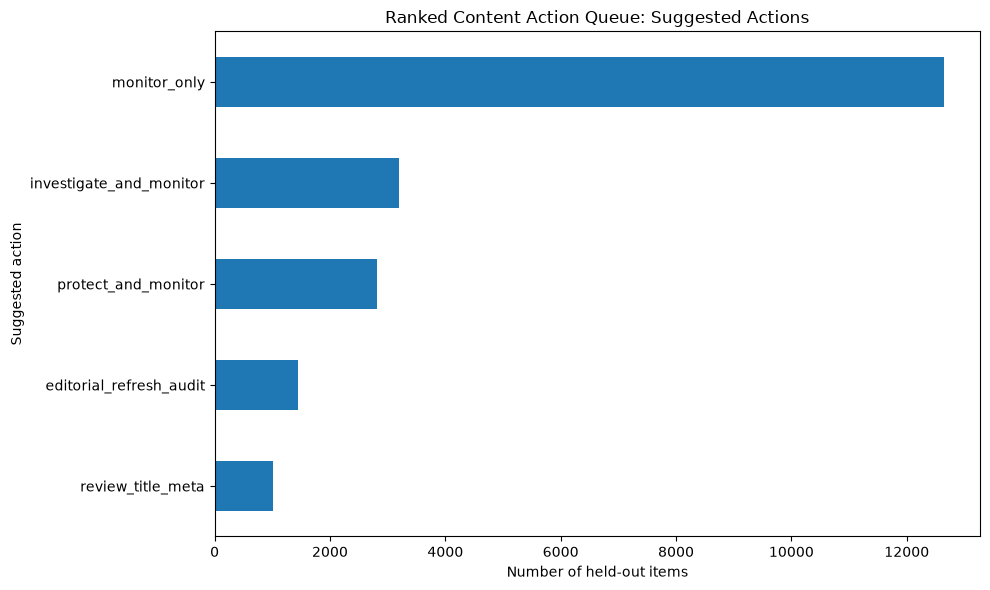

Queue exported: c:\Users\LENOVO\Downloads\ML-1\work\outputs\w07_ranked_action_queue.csv
Metrics exported: c:\Users\LENOVO\Downloads\ML-1\work\outputs\w07_playbook_metrics.json
Figure exported: c:\Users\LENOVO\Downloads\ML-1\work\figures\w07_action_distribution.png


In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# 1. Export the ranked queue.
queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"

queue.to_csv(
    queue_path,
    index=False
)

# 2. Export grouped validation metrics.
metrics_path = OUTPUT_DIR / "w07_playbook_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "project": "FlyRank content action playbook",
            "model": "Logistic Regression",
            "validation": grouped_metrics,
            "queue": {
                "rows": int(len(queue)),
                "priority_definition": (
                    "model_risk_score multiplied by log1p(impressions)"
                ),
                "priority_score_is_roi": False,
                "model_score_is_calibrated_probability": False
            }
        },
        f,
        indent=2
    )

# 3. Export a figure for the paper.
action_counts = (
    queue["suggested_action"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))
action_counts.plot(kind="barh")
plt.title("Ranked Content Action Queue: Suggested Actions")
plt.xlabel("Number of held-out items")
plt.ylabel("Suggested action")
plt.tight_layout()

figure_path = FIGURE_DIR / "w07_action_distribution.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Queue exported:", queue_path)
print("Metrics exported:", metrics_path)
print("Figure exported:", figure_path)

In [9]:
# Planning scenario, not a measured business result.
# Assumption: a human reviewer spends 15 minutes per item.

review_count = min(20, len(queue))
minutes_per_review = 15

estimated_review_hours = (
    review_count * minutes_per_review / 60
)

print("Top items considered:", review_count)
print("Assumed minutes per review:", minutes_per_review)
print("Estimated review time (hours):", round(estimated_review_hours, 2))

print(
    "\nValue interpretation: impressions represent search exposure, "
    "not revenue. The current feature frame does not contain a reliable "
    "monetary value per item, so this notebook does not claim ROI."
)

Top items considered: 20
Assumed minutes per review: 15
Estimated review time (hours): 5.0

Value interpretation: impressions represent search exposure, not revenue. The current feature frame does not contain a reliable monetary value per item, so this notebook does not claim ROI.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

### Self-check

This notebook is a research prototype and decision-support artifact.

The queue is ranked using a grouped holdout model score and a transparent exposure heuristic. The action mapping is rule-based and interpretable. All consequential editorial decisions remain subject to human review.

The decay/refresh discussion is directional and observational. It is not a causal claim.

The queue, metrics JSON, and figure are exported for the next week's paper. The queue CSV remains outside Git by design.

In [10]:
# Final integrity checks.

assert len(queue) > 0
assert queue["queue_rank"].is_monotonic_increasing
assert queue["priority_score"].notna().all()

assert train_clients.isdisjoint(test_clients)
assert grouped_metrics["client_overlap"] == 0

assert "position_worsened" not in queue.columns
assert "client_name" not in queue.columns
assert "url" not in queue.columns
assert "query" not in queue.columns

assert queue_path.exists()
assert metrics_path.exists()
assert figure_path.exists()

# Confirm that the queue includes reason codes and actions.
assert queue["reason_code"].notna().all()
assert queue["suggested_action"].notna().all()
assert queue["archetype"].notna().all()

print("All Week 7 self-checks passed.")
print("\nExport files:")
print(queue_path)
print(metrics_path)
print(figure_path)

All Week 7 self-checks passed.

Export files:
c:\Users\LENOVO\Downloads\ML-1\work\outputs\w07_ranked_action_queue.csv
c:\Users\LENOVO\Downloads\ML-1\work\outputs\w07_playbook_metrics.json
c:\Users\LENOVO\Downloads\ML-1\work\figures\w07_action_distribution.png
